<a href="https://colab.research.google.com/github/husthorng/AI-PLC-control/blob/main/Colab_%E5%8D%B3%E6%99%82%E6%8E%A5%E6%94%B6_ESP32_%E6%8C%AF%E5%8B%95%E8%B3%87%E6%96%99.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Google Colab 即時接收 ESP32 振動資料與建立 CSV

二、Colab Notebook *建立方式*

https://chatgpt.com/c/6b04be37-58ec-83e8-a4d9-6a1406735389
115husthorng

In [ ]:
#Cell 1：安裝及載入套件
!pip install -q numpy pandas scipy matplotlib

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import csv
import os
import time

from datetime import datetime
from zoneinfo import ZoneInfo
from scipy.signal import welch

from IPython.display import display, Javascript
from google.colab import output, files

print("CNC Vibration Data Logger Ready")

CNC Vibration Data Logger Ready


In [ ]:
#Cell 2：設定實驗參數
# ==============================
# CNC Experiment Configuration
# ==============================

BAUD_RATE = 921600

SAMPLE_RATE = 4000
SAMPLE_COUNT = 2048

# FFT frequency range
FREQ_MIN = 100
FREQ_MAX = 1000

# Time zone
TIME_ZONE = "Asia/Taipei"

# Output files
RAW_FILE = "/content/CNC_Raw_Data.csv"

FEATURE_FILE = "/content/CNC_Features.csv"

# Part labels
PART_NAMES = {
    0: "Part_A",
    1: "Part_B",
    2: "Part_C"
}

# Tool names
TOOL_NAMES = {
    "T01": "End_Mill",
    "T02": "Ball_Nose",
    "T03": "Drill"
}

print("Sample Rate:", SAMPLE_RATE)
print("Sample Count:", SAMPLE_COUNT)
print("Sampling Time:", SAMPLE_COUNT / SAMPLE_RATE)

Sample Rate: 4000
Sample Count: 2048
Sampling Time: 0.512


In [ ]:
#Cell 3：建立 CSV 欄位
raw_columns = [
    "Timestamp",
    "Run_ID",
    "Block",
    "Part_ID",
    "Tool_ID",
    "Sample_Index",
    "ADC"
]

feature_columns = [
    "Timestamp",
    "Run_ID",
    "Block",
    "Part_ID",
    "Tool_ID",
    "RPM",
    "Feed_Rate",
    "DOC",
    "X1_RMS",
    "X2_Std",
    "X3_PeakToPeak",
    "X4_CrestFactor",
    "X5_Kurtosis",
    "X6_DominantFreq",
    "X7_SpectralCentroid",
    "X8_BandPower",
    "Label"
]

# 建立空白 CSV
pd.DataFrame(
    columns=raw_columns
).to_csv(
    RAW_FILE,
    index=False,
    encoding="utf-8-sig"
)

pd.DataFrame(
    columns=feature_columns
).to_csv(
    FEATURE_FILE,
    index=False,
    encoding="utf-8-sig"
)

print("CSV files created")

CSV files created


In [ ]:
#3.2 Colab 特徵計算程式
def extract_features(adc_data):

    # Convert ADC to float
    x = np.array(adc_data, dtype=float)

    # Remove DC offset
    x = x - np.mean(x)

    # =========================
    # Time Domain
    # =========================

    rms = np.sqrt(np.mean(x**2))

    std = np.std(x)

    peak_to_peak = np.max(x) - np.min(x)

    peak = np.max(np.abs(x))

    crest_factor = (
        peak / rms if rms > 0 else 0
    )

    # Kurtosis (Pearson definition)
    if std > 0:
        kurtosis = np.mean((x / std)**4)
    else:
        kurtosis = 0

    # =========================
    # Frequency Domain
    # =========================

    freqs, psd = welch(
        x,
        fs=SAMPLE_RATE,
        window="hann",
        nperseg=1024,
        noverlap=512
    )

    # Ignore DC
    valid = freqs > 0

    dominant_index = np.argmax(psd[valid])

    dominant_freq = freqs[valid][dominant_index]

    # Spectral Centroid
    total_power = np.sum(psd)

    if total_power > 0:

        spectral_centroid = (
            np.sum(freqs * psd) / total_power
        )

    else:

        spectral_centroid = 0

    # Band Power: 100~1000 Hz
    band_mask = (
        (freqs >= FREQ_MIN) &
        (freqs <= FREQ_MAX)
    )

    if np.sum(band_mask) >= 2:

        band_power = np.trapezoid(
            psd[band_mask],
            freqs[band_mask]
        )

    else:

        band_power = 0

    return [
        rms,
        std,
        peak_to_peak,
        crest_factor,
        kurtosis,
        dominant_freq,
        spectral_centroid,
        band_power
    ]

In [ ]:
#Cell 4：建立 Serial 接收程式
from datetime import datetime
from zoneinfo import ZoneInfo

current_meta = None

received_blocks = 0
error_blocks = 0

def get_timestamp():

    return datetime.now(
        ZoneInfo(TIME_ZONE)
    ).isoformat(timespec="milliseconds")


def receive_line(line):

    global current_meta
    global received_blocks
    global error_blocks

    line = line.strip()

    if not line:
        return

    # =========================
    # Receive META
    # =========================

    if line.startswith("META,"):

        try:

            p = line.split(",")

            current_meta = {

                "Block": int(p[1]),

                "Run_ID": p[2],

                "Part_ID": int(p[3]),

                "Tool_ID": p[4],

                "RPM": int(p[5]),

                "Feed_Rate": int(p[6]),

                "DOC": float(p[7]),

                "Sample_Rate": int(p[8]),

                "Sample_Count": int(p[9])

            }

        except Exception as e:

            current_meta = None

            print("META Error:", e)

        return

    # =========================
    # Receive WAVE
    # =========================

    if line.startswith("WAVE,"):

        if current_meta is None:

            error_blocks += 1

            return

        try:

            values = line.split(",")

            adc = np.array(
                values[1:],
                dtype=np.float64
            )

            if len(adc) != current_meta["Sample_Count"]:

                raise ValueError(
                    "Sample count mismatch"
                )

            if current_meta["Sample_Rate"] != SAMPLE_RATE:

                raise ValueError(
                    "Sample rate mismatch"
                )

            timestamp = get_timestamp()

            meta = current_meta

            # =====================
            # Save Raw Data
            # =====================

            raw_df = pd.DataFrame({

                "Timestamp": timestamp,

                "Run_ID": meta["Run_ID"],

                "Block": meta["Block"],

                "Part_ID": meta["Part_ID"],

                "Tool_ID": meta["Tool_ID"],

                "Sample_Index": np.arange(len(adc)),

                "ADC": adc

            })

            raw_df.to_csv(

                RAW_FILE,

                mode="a",

                header=False,

                index=False,

                encoding="utf-8-sig"

            )

            # =====================
            # Feature Extraction
            # =====================

            features = extract_features(adc)

            feature_row = {

                "Timestamp": timestamp,

                "Run_ID": meta["Run_ID"],

                "Block": meta["Block"],

                "Part_ID": meta["Part_ID"],

                "Tool_ID": meta["Tool_ID"],

                "RPM": meta["RPM"],

                "Feed_Rate": meta["Feed_Rate"],

                "DOC": meta["DOC"]

            }

            for i, value in enumerate(features):

                feature_row[
                    f"X{i+1}_" + [
                        "RMS",
                        "Std",
                        "PeakToPeak",
                        "CrestFactor",
                        "Kurtosis",
                        "DominantFreq",
                        "SpectralCentroid",
                        "BandPower"
                    ][i]
                ] = value

            feature_row["Label"] = meta["Part_ID"]

            pd.DataFrame(
                [feature_row]
            ).to_csv(

                FEATURE_FILE,

                mode="a",

                header=False,

                index=False,

                encoding="utf-8-sig"

            )

            received_blocks += 1

            if received_blocks % 10 == 0:

                print(
                    "Received:",
                    received_blocks,
                    "Blocks |",
                    "Part:",
                    PART_NAMES.get(meta["Part_ID"], "Unknown"),
                    "| Tool:",
                    TOOL_NAMES.get(meta["Tool_ID"], "Unknown")
                )

        except Exception as e:

            error_blocks += 1

            print("WAVE Error:", e)

        return

    # =========================
    # Receive END
    # =========================

    if line == "END":

        current_meta = None

        return


output.register_callback(
    "cnc.receive_line",
    receive_line
)

print("Serial Receiver Callback Ready")

Serial Receiver Callback Ready


In [ ]:
#Cell 5：建立連線按鈕
display(Javascript(r"""
(() => {

    const root = element;

    let port = null;
    let reader = null;
    let running = false;

    const status = document.createElement("p");

    status.innerText = "尚未連接 ESP32";

    const connectBtn = document.createElement("button");

    connectBtn.innerText = "連接 ESP32";

    const stopBtn = document.createElement("button");

    stopBtn.innerText = "停止記錄";

    stopBtn.disabled = true;

    root.appendChild(connectBtn);
    root.appendChild(stopBtn);
    root.appendChild(status);

    connectBtn.onclick = async () => {

        try {

            port = await navigator.serial.requestPort();

            await port.open({
                baudRate: 921600
            });

            reader = port.readable.getReader();

            running = true;

            connectBtn.disabled = true;
            stopBtn.disabled = false;

            status.innerText = "ESP32 已連接，正在接收資料";

            const decoder = new TextDecoder();

            let buffer = "";

            while (running) {

                const {value, done} = await reader.read();

                if (done) break;

                buffer += decoder.decode(value, {
                    stream: true
                });

                const lines = buffer.split(/\r?\n/);

                buffer = lines.pop();

                for (const line of lines) {

                    if (line.trim()) {

                        await google.colab.kernel.invokeFunction(
                            "cnc.receive_line",
                            [line],
                            {}
                        );

                    }
                }
            }

        } catch (error) {

            status.innerText = "連線錯誤：" + error.message;

        } finally {

            connectBtn.disabled = false;
            stopBtn.disabled = true;

        }
    };

    stopBtn.onclick = async () => {

        running = false;

        try {

            if (reader) {

                await reader.cancel();

                reader.releaseLock();

            }

            if (port) {

                await port.close();

            }

        } catch (error) {

            console.log(error);

        }

        status.innerText = "資料記錄已停止";

    };

})();
"""))

<IPython.core.display.Javascript object>

Received: 10 Blocks | Part: Part_A | Tool: End_Mill
Received: 20 Blocks | Part: Part_A | Tool: End_Mill
Received: 30 Blocks | Part: Part_A | Tool: End_Mill
Received: 40 Blocks | Part: Part_A | Tool: End_Mill
Received: 50 Blocks | Part: Part_A | Tool: End_Mill
Received: 60 Blocks | Part: Part_A | Tool: End_Mill
Received: 70 Blocks | Part: Part_A | Tool: End_Mill
Received: 80 Blocks | Part: Part_A | Tool: End_Mill
Received: 90 Blocks | Part: Part_A | Tool: End_Mill
Received: 100 Blocks | Part: Part_A | Tool: End_Mill
Received: 110 Blocks | Part: Part_A | Tool: End_Mill
Received: 120 Blocks | Part: Part_A | Tool: End_Mill
Received: 130 Blocks | Part: Part_A | Tool: End_Mill
Received: 140 Blocks | Part: Part_A | Tool: End_Mill
Received: 150 Blocks | Part: Part_A | Tool: End_Mill
Received: 160 Blocks | Part: Part_A | Tool: End_Mill
Received: 170 Blocks | Part: Part_A | Tool: End_Mill
Received: 180 Blocks | Part: Part_A | Tool: End_Mill
Received: 190 Blocks | Part: Part_A | Tool: End_Mill
Re

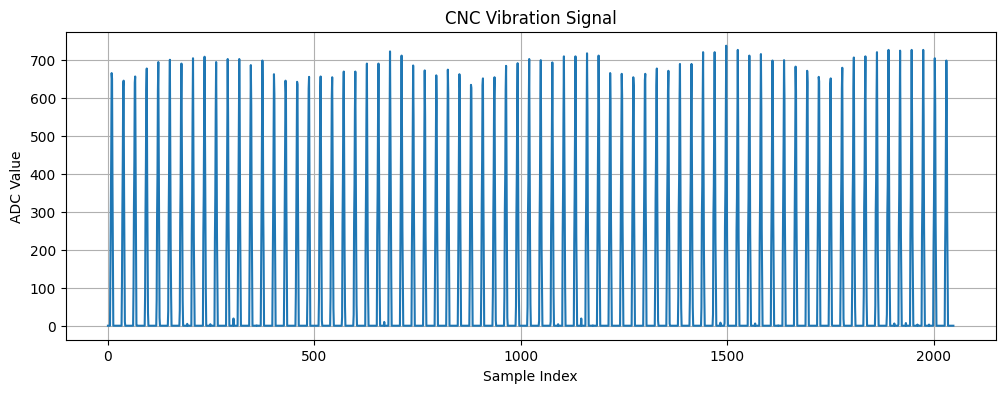

In [ ]:
#六、即時振動波形監控
# Load collected raw data

df = pd.read_csv(RAW_FILE)

# Select latest block

latest = df[
    df["Block"] == df["Block"].max()
]

plt.figure(figsize=(12, 4))

plt.plot(
    latest["Sample_Index"],
    latest["ADC"]
)

plt.title("CNC Vibration Signal")

plt.xlabel("Sample Index")

plt.ylabel("ADC Value")

plt.grid(True)

plt.show()

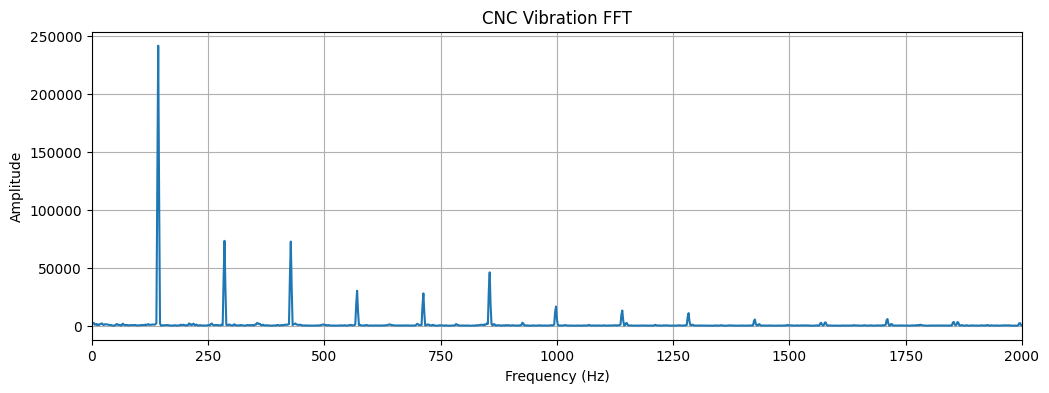

In [ ]:
#七、FFT 頻譜圖
df = pd.read_csv(RAW_FILE)

latest_block = df["Block"].max()

adc = df[
    df["Block"] == latest_block
]["ADC"].values

x = adc - np.mean(adc)

fft = np.fft.rfft(
    x * np.hanning(len(x))
)

freq = np.fft.rfftfreq(
    len(x),
    d=1/SAMPLE_RATE
)

amplitude = np.abs(fft)

plt.figure(figsize=(12, 4))

plt.plot(freq, amplitude)

plt.xlim(0, 2000)

plt.title("CNC Vibration FFT")

plt.xlabel("Frequency (Hz)")

plt.ylabel("Amplitude")

plt.grid(True)

plt.show()

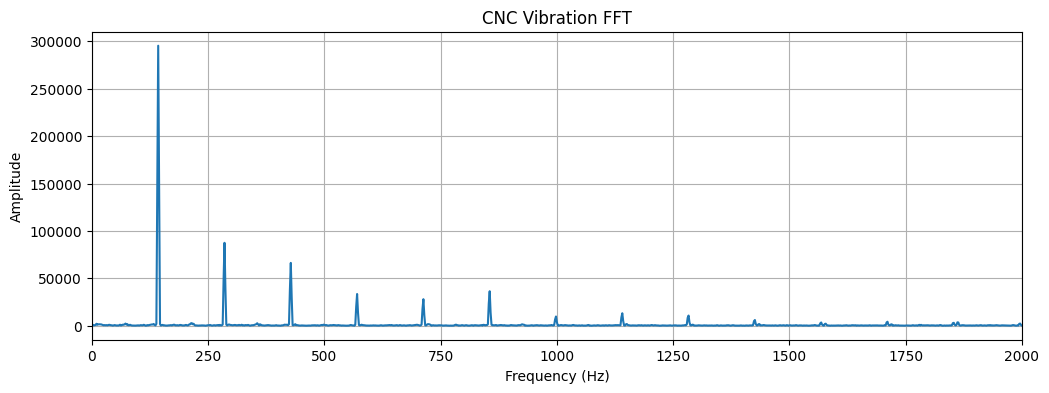

In [ ]:
#七、FFT 頻譜圖
df = pd.read_csv(RAW_FILE)

latest_block = df["Block"].max()

adc = df[
    df["Block"] == latest_block
]["ADC"].values

x = adc - np.mean(adc)

fft = np.fft.rfft(
    x * np.hanning(len(x))
)

freq = np.fft.rfftfreq(
    len(x),
    d=1/SAMPLE_RATE
)

amplitude = np.abs(fft)

plt.figure(figsize=(12, 4))

plt.plot(freq, amplitude)

plt.xlim(0, 2000)

plt.title("CNC Vibration FFT")

plt.xlabel("Frequency (Hz)")

plt.ylabel("Amplitude")

plt.grid(True)

plt.show()

In [ ]:
#八、資料收集狀態監控
print("==============================")
print(" CNC DATA COLLECTION STATUS")
print("==============================")

print("Received Blocks:", received_blocks)

print("Error Blocks:", error_blocks)

if os.path.exists(RAW_FILE):

    print(
        "Raw CSV Size:",
        round(os.path.getsize(RAW_FILE)/1024, 2),
        "KB"
    )

if os.path.exists(FEATURE_FILE):

    print(
        "Feature CSV Size:",
        round(os.path.getsize(FEATURE_FILE)/1024, 2),
        "KB"
    )

 CNC DATA COLLECTION STATUS
Received Blocks: 81
Error Blocks: 1
Raw CSV Size: 8982.88 KB
Feature CSV Size: 14.99 KB


In [ ]:
#九、下載 CSV 檔案
print("Download CNC Raw Data")

files.download(RAW_FILE)

print("Download CNC Feature Data")

files.download(FEATURE_FILE)

Download CNC Raw Data


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download CNC Feature Data


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>